In [1]:
import pandas as pd
import numpy as np

np.random.seed(42)
n = 500

bidhaa = {
    "Sukari": 3200, "Unga": 2800, "Mchele": 3500, "Mafuta": 6000,
    "Sabuni": 1500, "Chumvi": 1000, "Maji": 1000, "Soda": 1200,
}

df = pd.DataFrame({
    "Order ID": range(1001, 1001 + n),
    "Order Date": pd.date_range("2024-01-01", "2024-06-30", periods=n).strftime("%Y-%m-%d"),
    "Product": np.random.choice(list(bidhaa.keys()), n),
    "Quantity": np.random.randint(1, 20, n),
    "Branch": np.random.choice(["Dar es Salaam", "Arusha", "Mwanza"], n),
})
df["Price"] = df["Product"].map(bidhaa)

# ---- Makosa ya kuweka kwa makusudi ----
df.loc[5:14, "Product"] = df.loc[5:14, "Product"].str.lower() + " "   # nafasi + herufi ndogo
df.loc[20:29, "Product"] = df.loc[20:29, "Product"].str.upper()       # herufi kubwa
df.loc[40:55, "Price"] = np.nan                                       # bei tupu
df.loc[100, "Price"] = -3200                                          # bei hasi
df.loc[200, "Quantity"] = 900                                         # outlier
df = pd.concat([df, df.iloc[300:310]], ignore_index=True)             # duplicates

df.to_csv("sales_raw.csv", index=False)
print(df.shape)
df.head()

(510, 6)


,Order ID,Order Date,Product,Quantity,Branch,Price
0,1001,2024-01-01,Maji,1,Arusha,1000.0
1,1002,2024-01-01,Mafuta,3,Arusha,6000.0
2,1003,2024-01-01,Sabuni,18,Mwanza,1500.0
3,1004,2024-01-02,Maji,10,Dar es Salaam,1000.0
4,1005,2024-01-02,Mchele,3,Dar es Salaam,3500.0


In [12]:
df.info()
print(df.isnull().sum())
print("Duplicates", df.duplicated().sum())
print(df.describe())
      

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Order ID    500 non-null    int64         
 1   Order Date  500 non-null    datetime64[us]
 2   Product     500 non-null    str           
 3   Quantity    500 non-null    int32         
 4   Branch      500 non-null    str           
 5   Price       484 non-null    float64       
dtypes: datetime64[us](1), float64(1), int32(1), int64(1), str(2)
memory usage: 28.4 KB
Order ID       0
Order Date     0
Product        0
Quantity       0
Branch         0
Price         16
dtype: int64
Duplicates 0
          Order ID                  Order Date    Quantity        Price
count   500.000000                         500  500.000000   484.000000
mean   1250.500000  2024-03-31 00:02:52.800000   11.834000  2627.066116
min    1001.000000         2024-01-01 00:00:00    1.000000 -3200.000000
25%    1125.750000 

In [8]:
df["Product"].value_counts()

Product
Mafuta     75
Sukari     73
Soda       69
Mchele     62
Chumvi     61
Maji       56
Sabuni     49
Unga       45
mchele      3
CHUMVI      3
soda        2
sabuni      2
maji        2
UNGA        2
SODA        2
MAFUTA      2
unga        1
SABUNI      1
Name: count, dtype: int64

In [9]:
df = df.drop_duplicates()
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Product"] = df["Product"].str.strip().str.title()
print(df.shape)
df["Product"].value_counts()

(500, 6)


Product
Mafuta    76
Soda      72
Sukari    71
Mchele    64
Chumvi    62
Maji      58
Sabuni    51
Unga      46
Name: count, dtype: int64

In [15]:
#Bei sahihi ya kila bidhaa (median ya bei halali 
bei_sahihi = df[df["Price"]> 0].groupby("Product")["Price"].median()

#Badilisha bei hasi kuwa tupu kwanza
df.loc[df["Price"] <= 0, "Price"] = np.nan

#Jaza zote tupu kwa bei ya bidhaa husika
df["Price"] = df["Price"].fillna(df["Product"].map(bei_sahihi))
print(df["Price"].isnull().sum())
print(df["Price"].min())

0
1000.0


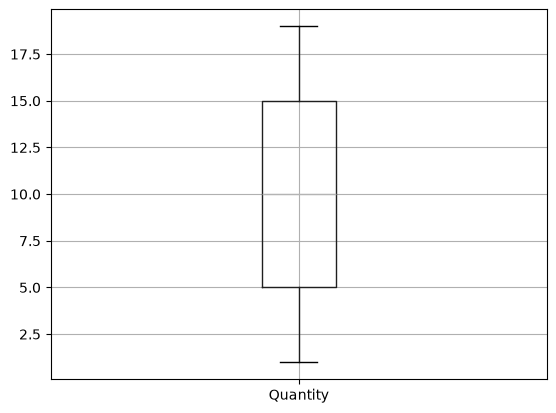

In [20]:
import matplotlib.pyplot as plt
df.boxplot(column = "Quantity")
plt.show()

In [17]:
print(df["Quantity"].describe())
print(df[df["Quantity"] > 50])

count    500.000000
mean      11.834000
std       40.198636
min        1.000000
25%        5.000000
50%       10.000000
75%       15.000000
max      900.000000
Name: Quantity, dtype: float64
     Order ID Order Date Product  Quantity         Branch   Price
200      1201 2024-03-13    Maji       900  Dar es Salaam  1000.0


In [19]:
median_qty = df.loc[df["Quantity"] <50,"Quantity"].median()
df.loc[df["Quantity"] >50,"Quantity"] = median_qty
print(df["Quantity"].max())

19


In [21]:
df["Total Sales"] = df["Price"] * df["Quantity"]
df["Month"] = df["Order Date"].dt.month_name()
print(df[["Product", "Price", "Quantity", "Total Sales", "Month"]].head())
print("Jumla ya mauzo:", df["Total Sales"].sum())
      

  Product   Price  Quantity  Total Sales    Month
0    Maji  1000.0         1       1000.0  January
1  Mafuta  6000.0         3      18000.0  January
2  Sabuni  1500.0        18      27000.0  January
3    Maji  1000.0        10      10000.0  January
4  Mchele  3500.0         3      10500.0  January
Jumla ya mauzo: 13216800.0


In [27]:
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.month_name()
print(df[["Order Date", "Month", "Month Name", "Total Sales"]].head())

  Order Date  Month Month Name  Total Sales
0 2024-01-01      1    January       1000.0
1 2024-01-01      1    January      18000.0
2 2024-01-01      1    January      27000.0
3 2024-01-02      1    January      10000.0
4 2024-01-02      1    January      10500.0


In [25]:
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

In [26]:
df.describe()

,Order ID,Order Date,Quantity,Price,Total Sales,Month
count,500.000000,500,500.000000,500.0000,500.000000,500.000000
mean,1250.500000,2024-03-31 00:02:52.800000,10.054000,2637.8000,26433.600000,3.486000
min,1001.000000,2024-01-01 00:00:00,1.000000,1000.0000,1000.000000,1.000000
25%,1125.750000,2024-02-14 18:00:00,5.000000,1200.0000,9600.000000,2.000000
50%,1250.500000,2024-03-31 00:00:00,10.000000,2800.0000,18000.000000,3.000000
75%,1375.250000,2024-05-15 06:00:00,15.000000,3500.0000,36000.000000,5.000000
max,1500.000000,2024-06-30 00:00:00,19.000000,6000.0000,114000.000000,6.000000
std,144.481833,NaN,5.650038,1714.6753,24818.043872,1.706349


In [30]:
# 1. mauzo yote
print("Jumla ya mauzo:", df["Total Sales"].sum())

# 2. Bidhaa 3 zinazoongoza 
print(df.groupby("Product")["Total Sales"].sum().sort_values(ascending=False).head(3))

# 3. Mauzo ya mwezi ( yamepangwa kwa mpangilio  wa muda)
print(df.groupby(["Month", "Month Name"])["Total Sales"].sum())

# 4. Tawi linaloongoza 
print(df.groupby("Branch")["Total Sales"].sum().sort_values(ascending=False))
      

Jumla ya mauzo: 13216800.0
Product
Mafuta    4626000.0
Sukari    2268800.0
Mchele    2114000.0
Name: Total Sales, dtype: float64
Month  Month Name
1      January       2405000.0
2      February      2110700.0
3      March         2083800.0
4      April         2150300.0
5      May           2440300.0
6      June          2026700.0
Name: Total Sales, dtype: float64
Branch
Dar es Salaam    4877300.0
Mwanza           4551700.0
Arusha           3787800.0
Name: Total Sales, dtype: float64


In [34]:
df.to_excel("Sales1_clean.xlsx", index=False)
print(df.shape)
print(df.dtypes)

(500, 9)
Order ID                int64
Order Date     datetime64[us]
Product                   str
Quantity                int32
Branch                    str
Price                 float64
Total Sales           float64
Month                   int32
Month Name                str
dtype: object


In [32]:
!pip install openpyxl